# Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective:** Understand the relationship between product categories and their best-seller status.

### Crosstab Analysis:
* Create a crosstab between the product category and the isBestSeller status.
* Are there categories where being a best-seller is more prevalent?
* Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

### Statistical Tests:
* Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
* Compute Cramér's V to understand the strength of association between best-seller status and category.

### Visualizations:
* Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [1]:
import pandas as pd
from scipy.stats import chi2_contingency
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load dataset 
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
# Create the crosstab (contingency table)
# This counts how many products are/aren't Best Sellers in each category

ct = pd.crosstab(df['category'], df['isBestSeller'])

In [4]:
ct.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [5]:
# Calculate proportions (Percentage of Best Sellers per category)
# We divide the 'True' column by the sum of both columns (Total)

ct_prop = ct.div(ct.sum(axis=1), axis=0)

In [6]:
ct_prop.head()


isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811


In [7]:
# Sort by the 'True' column (Best Sellers) in descending order to see top performers

ct_prop_sorted = ct_prop.sort_values(by=True, ascending=False)

ct_prop_sorted.head()

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339


## Grocery,Smart Home Security & Lighting and Health & Personal Care are the categories where being a best-seller is more prevalent.

In [8]:
# Conduct the Chi-square test
# This returns the chi-stat, the p-value, degrees of freedom, and expected frequencies
chi2, p, dof, expected = chi2_contingency(ct)

In [9]:

chi2, p

(np.float64(36540.20270061387), np.float64(0.0))

In [10]:
print(f"Chi-square: {chi2:.2f}, p-value: {p:.4f}")

Chi-square: 36540.20, p-value: 0.0000


## The Chi-square test returned a p-value of 0.0000, which indicates that the relationship between product category and best-seller status is highly significant. This means that the likelihood of a product achieving best-seller status is not random; rather, it is strongly tied to the category the product belongs to.

<Axes: xlabel='category'>

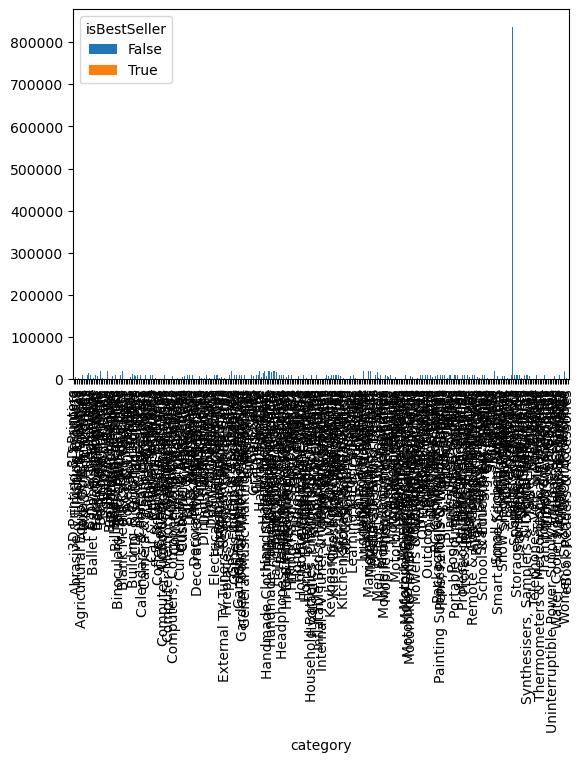

In [11]:
# Plotting a stacked bar chart for the 'crosstab_result' data
ct.plot(kind="bar", stacked=True)


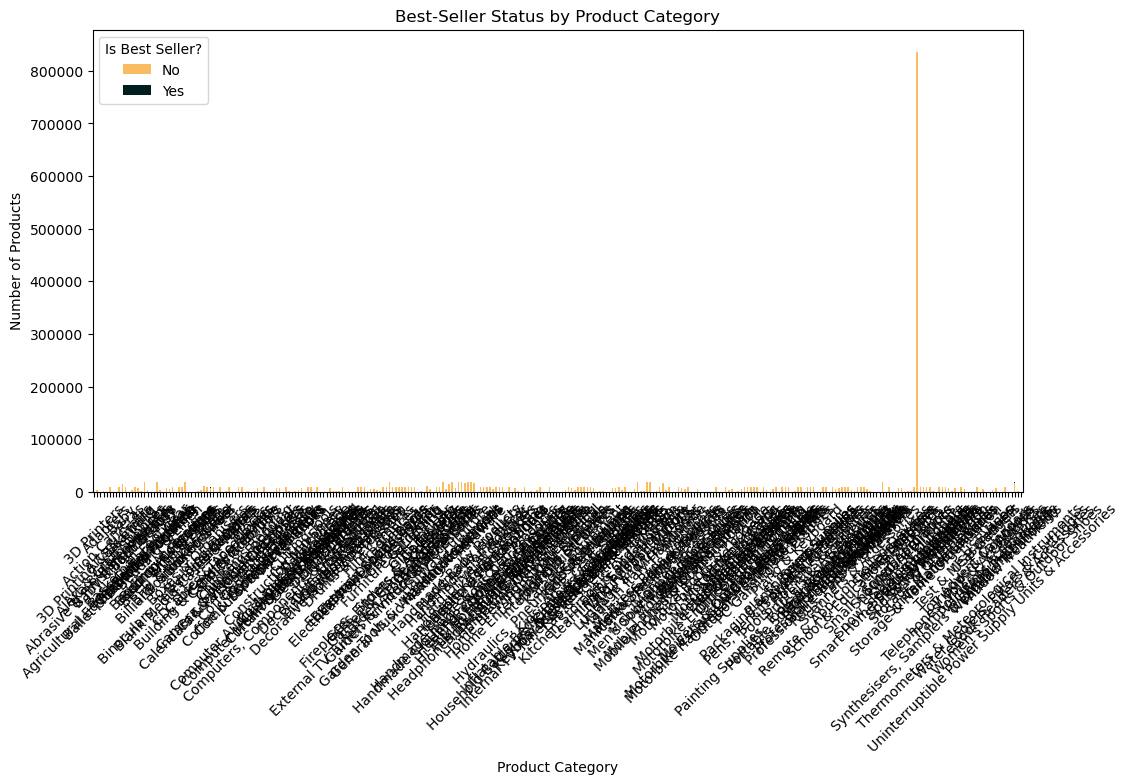

In [12]:
# Plotting a stacked bar chart
# 'kind=bar' makes it a bar chart, 'stacked=True' puts the segments on top of each other
ct.plot(kind='bar', stacked=True, figsize=(12, 6), color=['#f9bc60', '#001e1d'])

plt.title('Best-Seller Status by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.legend(title='Is Best Seller?', labels=['No', 'Yes'])
plt.xticks(rotation=45) # Rotates category names so they don't overlap
plt.show()

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective:** Investigate how different product categories influence product prices.

### Preliminary Step: Remove outliers in product prices.
For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
* **Hint:** you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

### Violin Plots:
* Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
* Which product category tends to have the highest median price? Don't filter here by top categories.

### Bar Charts:
* Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
* Which product category commands the highest average price? Don't filter here by top categories.

### Box Plots:
* Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
* Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [13]:
# Step 1: Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

# Step 2: Calculate the IQR (Interquartile Range)
IQR = Q3 - Q1

# Step 3: Define the lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Step 4: Filter the dataframe to keep only the data within the bounds
df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Original rows: {len(df)}, Rows after outlier removal: {len(df_clean)}")

Original rows: 2443651, Rows after outlier removal: 2115963


<Axes: xlabel='price', ylabel='category'>

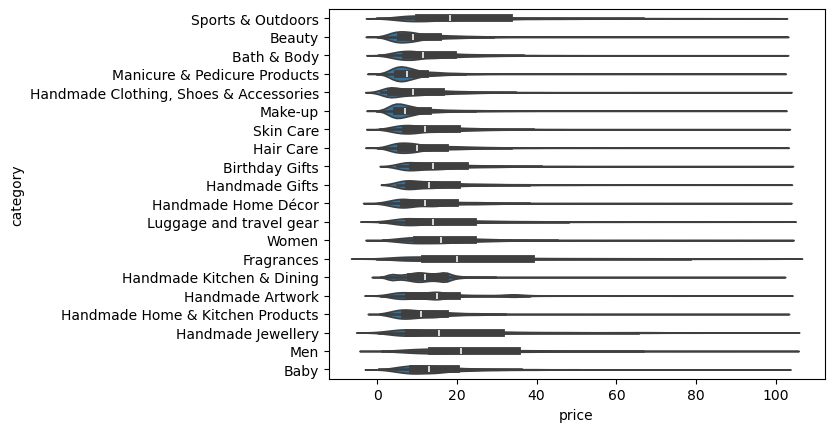

In [14]:
# Pass the top 20 list directly into the 'order' parameter
sns.violinplot(
    data=df_clean, 
    x='price', 
    y='category', 
    order=df_clean['category'].value_counts().iloc[:20].index
)

In [15]:
# 1. Group by category to calculate the median price
# 2. Sort the values in descending order
# 3. .idxmax() specifically returns the name (index) of the highest value
highest_median_price_cat = df_clean.groupby('category')['price'].median().idxmax()

# To see the actual price associated with that category:
highest_median_price_value = df_clean.groupby('category')['price'].median().max()

print(f"The category with the highest median price is: {highest_median_price_cat}")
print(f"The median price for this category is: £{highest_median_price_value:.2f}")

The category with the highest median price is: Desktop PCs
The median price for this category is: £74.00


<Axes: xlabel='price', ylabel='category'>

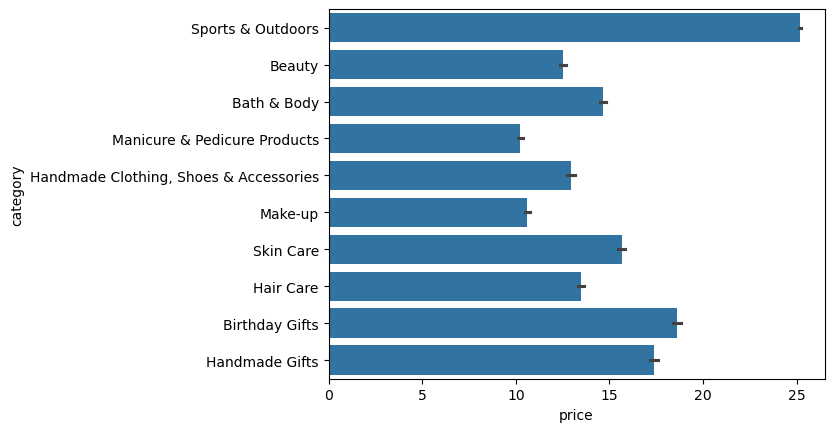

In [16]:
# Calculate the order once
top_10_names = df_clean['category'].value_counts().nlargest(10).index

# Plot directly from the full cleaned dataframe
sns.barplot(
    data=df_clean, 
    y='category', 
    x='price', 
    order=top_10_names
)

In [17]:
# Group by every category and find the mean price
avg_prices_all = df_clean.groupby('category')['price'].mean()

# Identify the category name and its specific price
highest_avg_cat = avg_prices_all.idxmax()
highest_avg_value = avg_prices_all.max()

print(f"The category with the highest average price is: {highest_avg_cat}")
print(f"The average price for this category is: £{highest_avg_value:.2f}")


The category with the highest average price is: Motherboards
The average price for this category is: £68.77


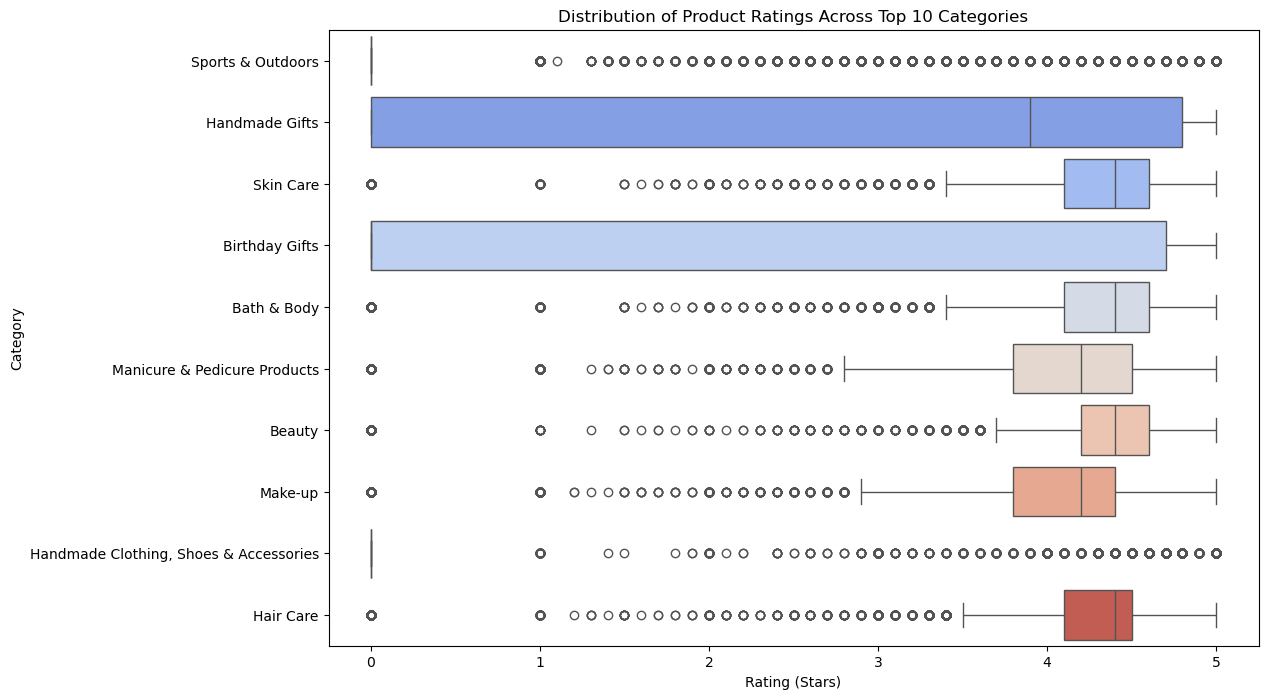

In [18]:
# 1. Identify the top 10 categories by product count
top_10_cats = df_clean['category'].value_counts().nlargest(10).index

# 2. Create the box plot using your suggested style
plt.figure(figsize=(12, 8))
sns.boxplot(
    data=df_clean[df_clean['category'].isin(top_10_cats)], 
    x='stars', 
    y='category', 
    hue='category',
    palette="coolwarm",
    legend=False
)

plt.title('Distribution of Product Ratings Across Top 10 Categories')
plt.xlabel('Rating (Stars)')
plt.ylabel('Category')
plt.show()

In [19]:
# Group by every category and calculate the median rating
median_ratings = df_clean.groupby('category')['stars'].median()

# Find the category with the highest median
highest_rating_cat = median_ratings.idxmax()
highest_rating_value = median_ratings.max()

print(f"The category with the highest median rating is: {highest_rating_cat}")
print(f"The median rating for this category is: {highest_rating_value} stars")

The category with the highest median rating is: Computer Memory
The median rating for this category is: 4.7 stars


# Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective:** Analyze how product ratings (stars) correlate with product prices.

### Correlation Coefficients:
* Calculate the correlation coefficient between **price** and **stars**.
* Is there a significant correlation between product price and its rating?

### Visualizations:
* Use a scatter plot to visualize the relationship between product rating and price. 
    What patterns can you observe?

* Use a correlation heatmap to visualize correlations between all numerical variables.

* Examine if product prices typically follow a normal distribution using a QQ plot.





### Correlation Coefficients:

In [20]:
# Calculating the Pearson correlation coefficient between 'Price' and 'Stars' columns
correlation = df_clean['price'].corr(df_clean['stars'])
correlation

np.float64(-0.0776729987818131)

In [21]:
# Calculating the Spearman rank correlation between 'Price' and 'Stars' columns
correlation = df_clean['price'].corr(df_clean['stars'], method='spearman')
correlation

np.float64(-0.06679697280768324)

A correlation coefficient between -0.1 and +0.1 is generally considered "negligible" or "no relationship." This suggests that price is not a predictor of ratings. Knowing how much a product costs tells you almost nothing about whether a customer will give it 5 stars or 1 star.

### Visualizations:¶

<Axes: xlabel='stars', ylabel='price'>

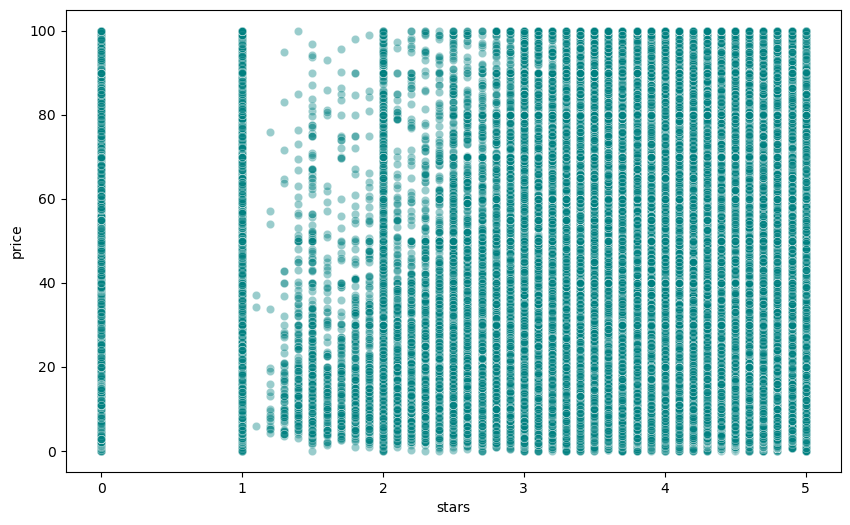

In [22]:
# Create the scatter plot

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='stars', y='price', alpha=0.4, color='teal')

The primary pattern is a **lack of a pattern**. This confirms that in your dataset, there is no "premium effect" where higher prices lead to higher ratings, nor is there a "budget penalty" where cheaper items are rated poorly. Customers seem to rate items based on how well they fulfill their specific purpose relative to their cost, rather than the absolute price.

In [27]:
# Create a new DataFrame with only numerical columns
df_clean_numerical = df.select_dtypes(include="number")

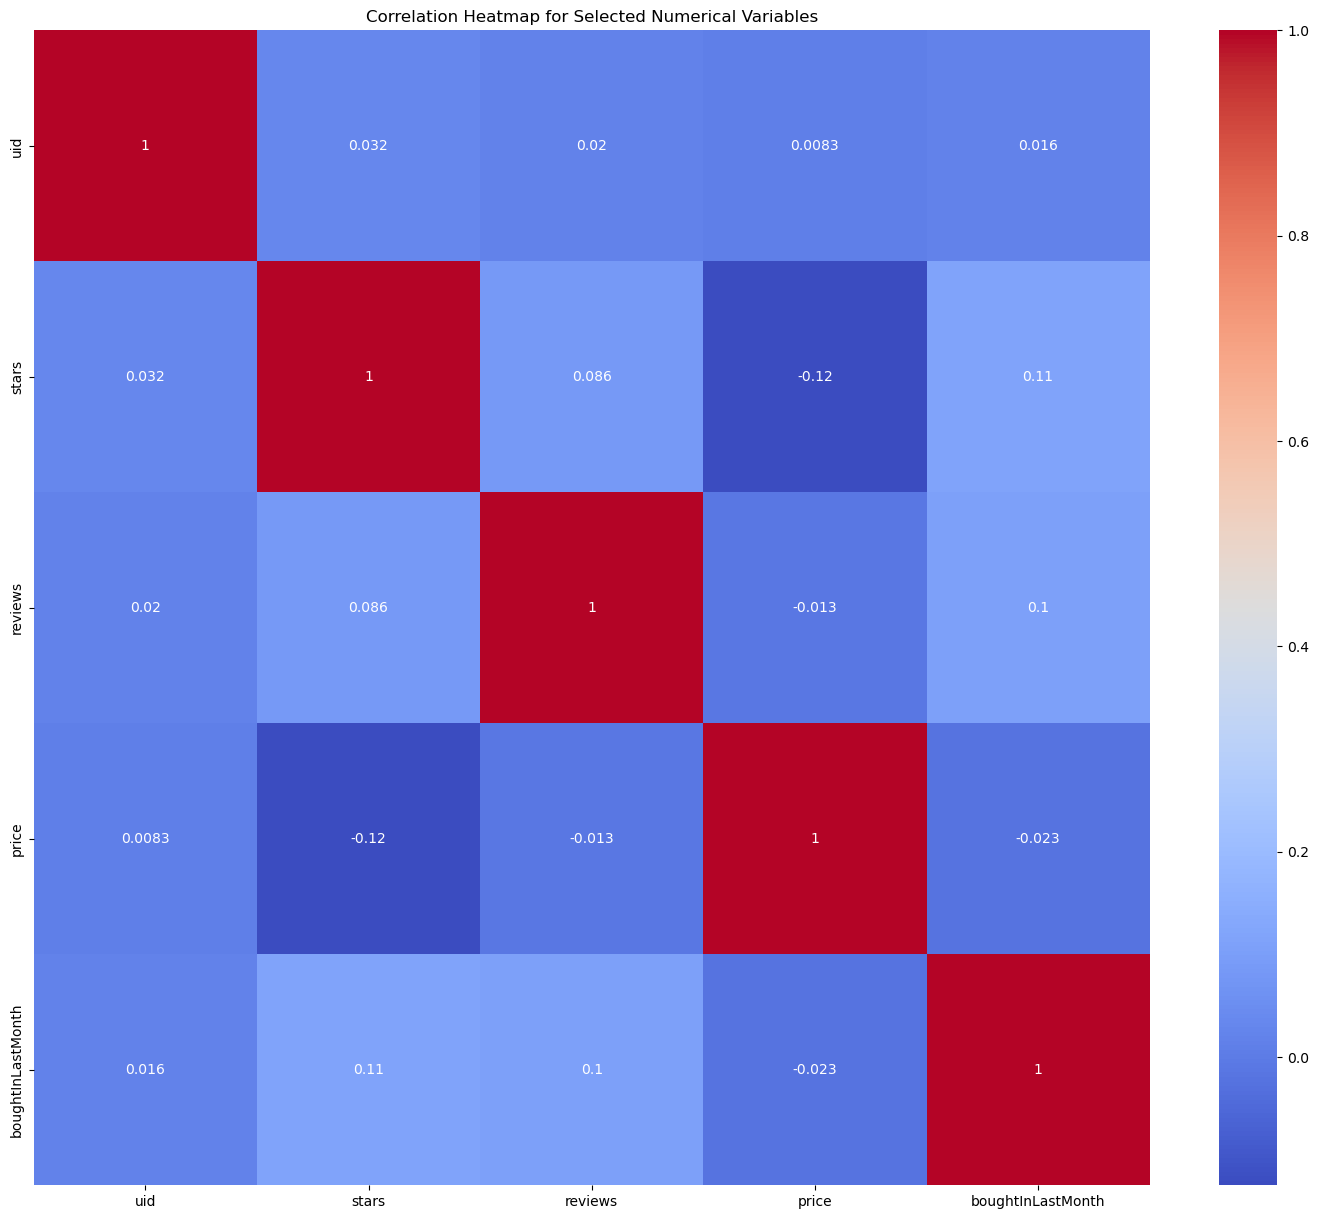

In [28]:
correlation_matrix = df_clean_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

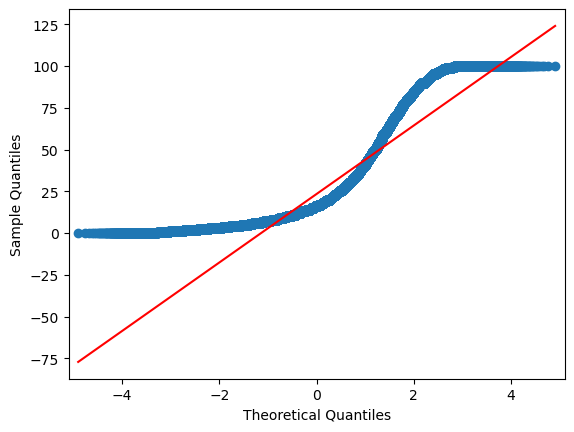

In [31]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'Price' to check if its distribution follows a normal distribution
sm.qqplot(df_clean['price'], line='s');

In our dataset, we will likely see the blue dots curve away from the red line significantly at the higher price points. This confirms that product prices do not follow a normal distribution—they follow a "Power Law" or "Skewed" distribution where most items are clustered at lower prices.

### Bonus:

Do the same analysis without taking out the outliers. What are your insights?

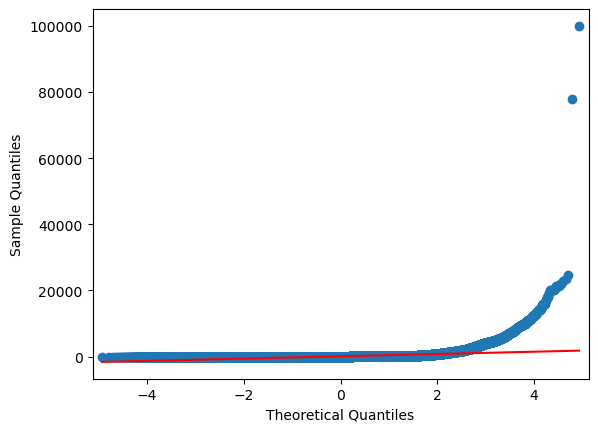

In [32]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'Price' to check if its distribution follows a normal distribution
sm.qqplot(df['price'], line='s');

The QQ plot of the original dataframe shows a dramatic departure from the theoretical normal line. The 'Hockey Stick' shape confirms an extreme right-skewed distribution. This visual evidence validates our decision to use non-parametric measures (like Spearman Correlation) and to perform outlier filtering to gain a clearer view of the typical consumer experience.

In [33]:
# Calculating the Pearson correlation coefficient between 'Price' and 'Stars' columns
correlation = df['price'].corr(df_clean['stars'])
correlation

np.float64(-0.0776729987818131)

In [34]:
# Calculating the Spearman rank correlation between 'Price' and 'Stars' columns
correlation = df['price'].corr(df_clean['stars'], method='spearman')
correlation

np.float64(-0.06679697280768324)

Sensitivity Analysis: We can prove that the Pearson correlation in the raw data is "unreliable" because it is easily manipulated by a handful of luxury items.

The "Truth" in Spearman: Since Spearman stays the same regardless of outliers, you can confidently conclude that price and stars are truly independent.

<Axes: xlabel='stars', ylabel='price'>

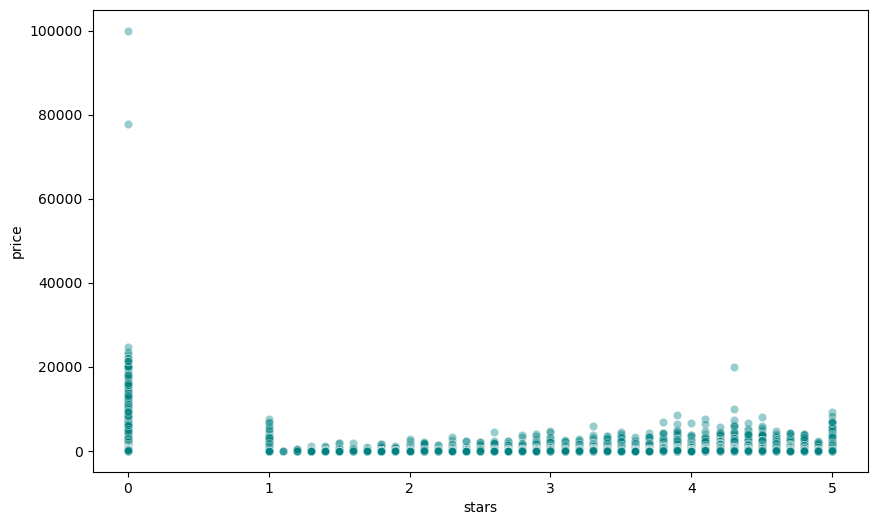

In [35]:
# Create the scatter plot

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='stars', y='price', alpha=0.4, color='teal')

In [36]:
# Create a new DataFrame with only numerical columns
df_numerical = df.select_dtypes(include="number")

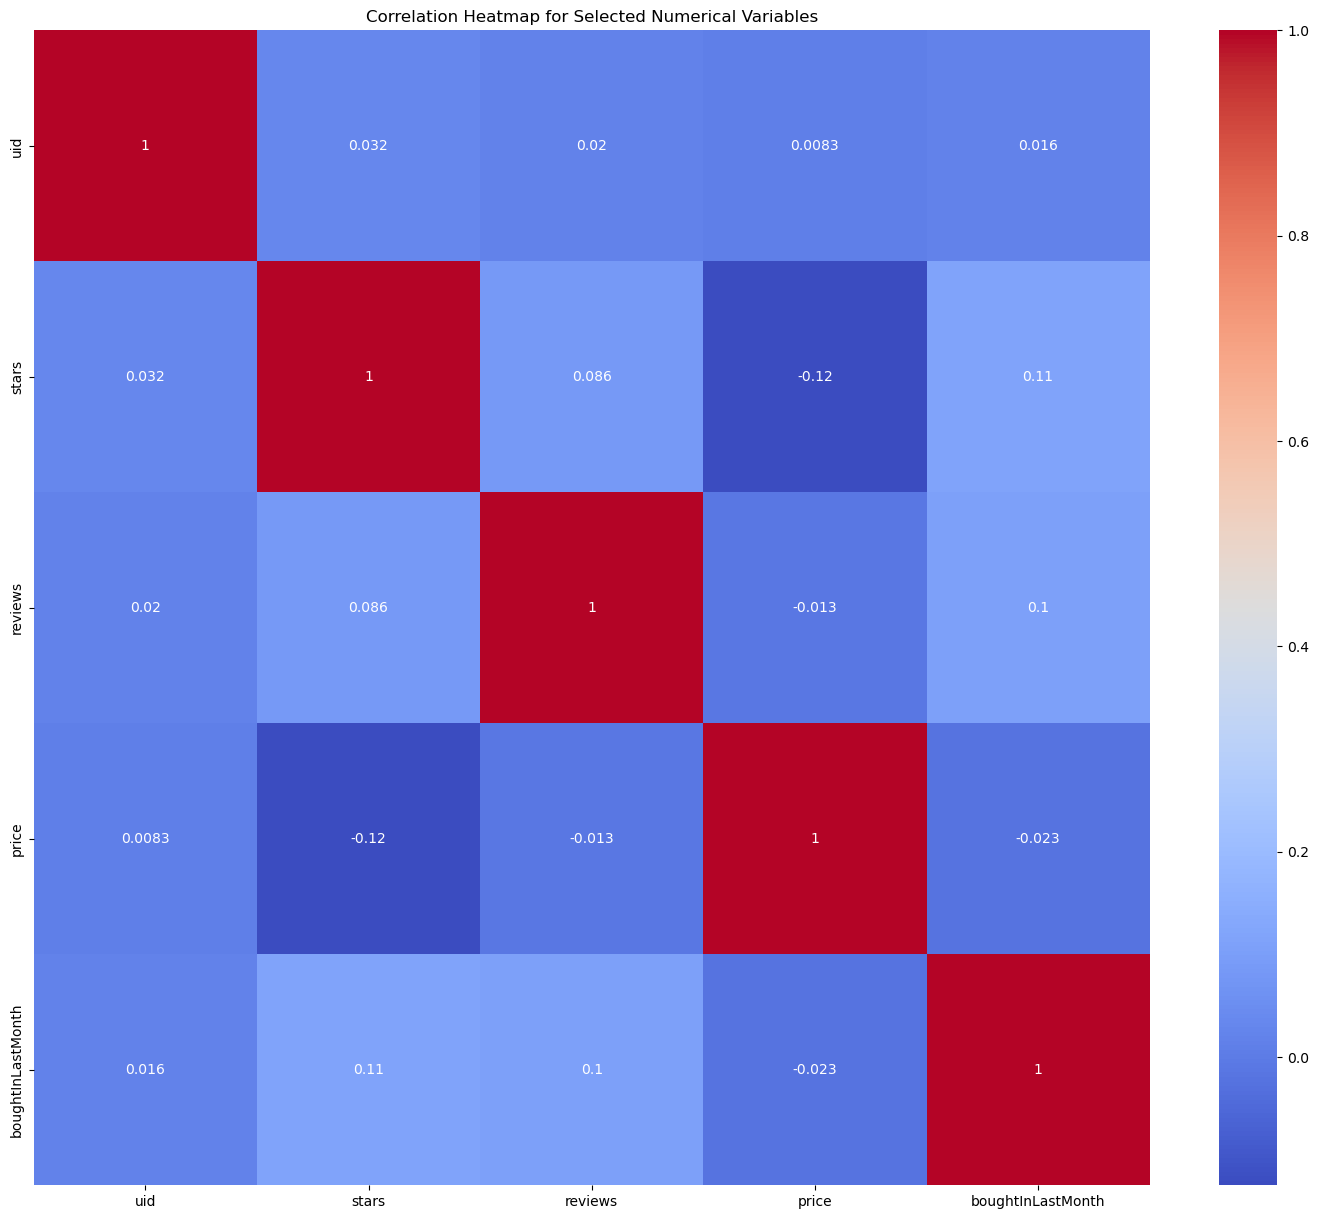

In [37]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()